<a href="https://colab.research.google.com/github/akshat280706/IP-LABS/blob/main/41080009_akshat_IP_LAB6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#241080009
#Akshat Chauhan
#IT

In [ ]:
from google.colab import files
uploaded=files.upload()
filename=next(iter(uploaded))

Saving for IP.jfif to for IP.jfif


In [ ]:
import cv2
import numpy as np
import heapq
from collections import Counter

og img: for IP.jfif
img dim: 640 x 480
no of pixel intensity: 256
og imgSize: 307200 bytes

og Grayscale img:


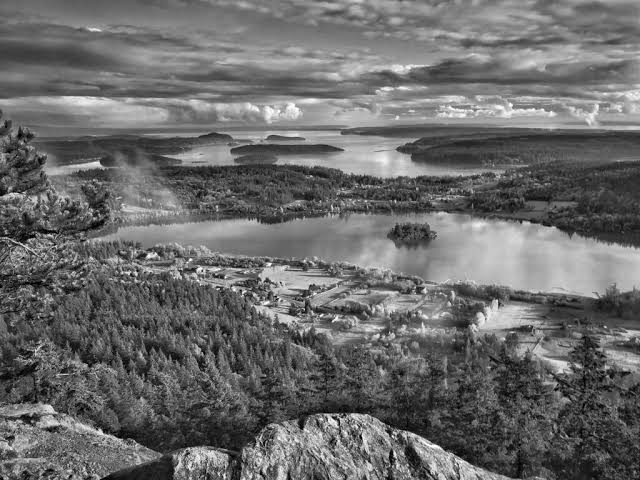


Huffman Coding Table:
Pixel Intensity | Frequency | Huffman Code
0 | 146 | 01001011101
1 | 30 | 0000111000010
2 | 43 | 1101111100011
3 | 42 | 1101111100000
4 | 58 | 000011100000
5 | 51 | 1111010100110
6 | 70 | 010010111001
7 | 78 | 101101011111
8 | 76 | 101101011100
9 | 89 | 111000111001
10 | 115 | 111111011110
11 | 109 | 111110011010
12 | 128 | 00011000110
13 | 158 | 11001111100
14 | 184 | 11101011100
15 | 173 | 11011111010
16 | 200 | 11110101000
17 | 260 | 0010101000
18 | 294 | 1000101110
19 | 285 | 0100101111
20 | 329 | 1101101000
21 | 375 | 1110001111
22 | 431 | 1111100111
23 | 501 | 000110000
24 | 535 | 001010101
25 | 545 | 010010110
26 | 633 | 110011110
27 | 651 | 110100010
28 | 709 | 110111111
29 | 755 | 111010110
30 | 863 | 111111010
31 | 846 | 111101011
32 | 934 | 111111100
33 | 941 | 111111101
34 | 991 | 00010000
35 | 992 | 00010001
36 | 1068 | 00101011
37 | 1111 | 01000110
38 | 1103 | 01000001
39 | 1207 | 10110100
40 | 1212 | 10110110
41 | 1253 | 11000101
42 | 1313 | 110100

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
img=cv2.imread(filename,cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Could not read the uploaded image.")

height,width=img.shape
pixels=img.flatten().tolist()

frequency = Counter(pixels)
print("og img:",filename)
print("img dim:",width,"x",height)
print("no of pixel intensity:",len(frequency))
print("og imgSize:",len(pixels),"bytes")

print("\nog Grayscale img:")
from google.colab.patches import cv2_imshow
cv2_imshow(img)

heap=[]
counter=0
for pixel,freq in sorted(frequency.items()):
    heapq.heappush(heap,(freq,counter,{pixel:""}))
    counter+=1

while len(heap)>1:
    f1,_,left=heapq.heappop(heap)
    f2,_,right=heapq.heappop(heap)
    merged={}

    for pixel,code in left.items():
        merged[pixel]="0"+code

    for pixel,code in right.items():
        merged[pixel]="1"+code

    heapq.heappush(heap,(f1+f2,counter,merged))
    counter+=1

codes=heap[0][2]

if len(codes)==1:
    pixel=next(iter(codes))
    codes[pixel]="0"

encoded="".join(codes[pixel] for pixel in pixels)

original_size=len(pixels)
original_bits=original_size*8

encoded_bits=len(encoded)
encoded_bytes=(encoded_bits+7)//8

table="\n".join(f"{pixel}:{codes[pixel]}" for pixel in sorted(codes))
table_bytes=len(table.encode("utf-8"))

compressed_size=encoded_bytes+table_bytes

print("\nHuffman Coding Table:")
print("Pixel Intensity | Frequency | Huffman Code")

for pixel in sorted(frequency):
    print(pixel,"|",frequency[pixel],"|",codes[pixel])
ratio=original_size/compressed_size if compressed_size else 0

saving=((original_size-compressed_size)/original_size*100 if original_size else 0)

print("\nog size:",original_bits,"bits")
print("Encoded DataSize:",encoded_bits,"bits")
print("Estimated Compressed Size:",compressed_size,"bytes")
print("Compression Ratio:",round(ratio,2),":1")
print("Space Saving:",round(saving,2),"%")

with open("compressed_huffman.txt","w") as f:
    f.write("Huffman Coding Table\n")
    f.write(table)
    f.write("\n\nEncoded Bitstream\n")
    f.write(encoded)

files.download("compressed_huffman.txt")